# Chapitre 3 - Cours 6 : event sourcing, CQRS et DataFrames

Dans tous les modèles vus jusqu'ici, on lit les données **sous la forme où on les a
écrites** : documents, lignes, sommets et arêtes. Ce dernier cours présente deux modèles
qui rompent avec cette symétrie. L'**event sourcing** écrit un journal d'événements
immuables et en dérive des vues optimisées pour la lecture (**CQRS**) ; les
**DataFrames** et les **matrices** servent l'analyse de données et l'apprentissage
automatique. Il couvre les sections *Event Sourcing and CQRS* et *DataFrames, Matrices,
and Arrays*, ainsi que la fin du résumé du chapitre.

**Plan.**

1. Écrire des événements, lire des vues.
2. Commandes, événements et projections en code.
3. Rejouer le journal : reconstruire, corriger, ajouter une vue.
4. Les pièges de l'event sourcing.
5. DataFrames, matrices et tableaux.

In [1]:
import hashlib
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels_ed2 as e2
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Écrire des événements, lire des vues (section *Event Sourcing and CQRS*)

**Le problème.** Dans une application complexe, il est parfois impossible de trouver
**une** représentation des données qui serve bien toutes les façons de les lire et de
les afficher. Prenons l'exemple du livre, un système de gestion de conférence : des
participants s'inscrivent et paient par carte, des entreprises achètent des places par
lots sur facture puis les attribuent, des places sont réservées aux orateurs et aux
sponsors, des réservations sont annulées, et l'organisateur change de salle (donc de
capacité). Calculer simplement le **nombre de places disponibles** devient une requête
délicate.

**L'idée.** Puisqu'on dérive de toute façon des représentations à partir d'autres
(l'ETL, les vues matérialisées...), choisissons deux représentations distinctes :

- pour l'**écriture**, la plus simple et la plus expressive possible : un **journal
  d'événements**. Chaque changement est encodé comme un enregistrement autonome
  (horodaté) **ajouté** à la fin d'une séquence. Les événements sont **immuables** : on ne
  les modifie ni ne les supprime jamais, on en ajoute d'autres qui les remplacent ;
- pour la **lecture**, autant de **vues matérialisées** (aussi appelées *projections* ou
  *modèles de lecture*) que nécessaire, chacune mise à jour à chaque nouvel événement.

Utiliser les événements comme **source de vérité** s'appelle l'**event sourcing** ;
maintenir des représentations séparées optimisées pour la lecture, dérivées de la
représentation optimisée pour l'écriture, s'appelle **CQRS** (*command query
responsibility segregation*). Ces termes viennent de la communauté DDD
(*domain-driven design*), mais l'idée est ancienne : la réplication de machine à états
(chapitre 10) repose sur le même principe.

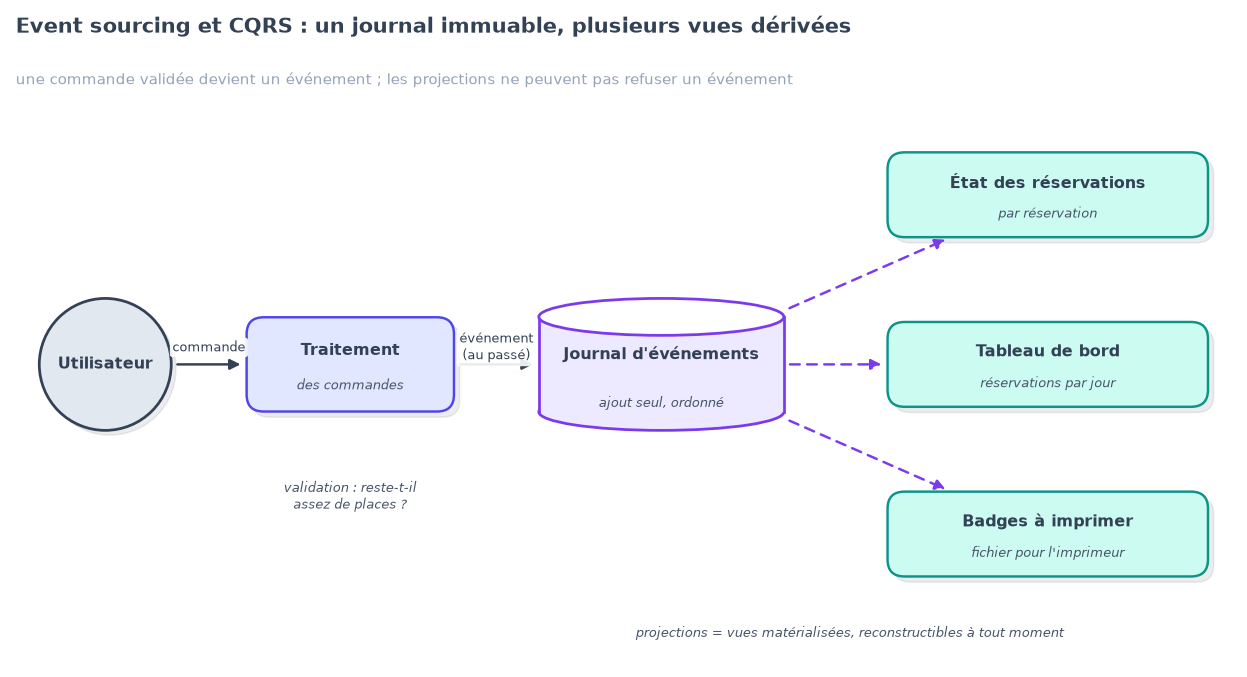

In [2]:
d = Diagram(13, 6.0, title="Event sourcing et CQRS : un journal immuable, plusieurs vues dérivées",
            subtitle="une commande validée devient un événement ; les projections ne peuvent pas refuser un événement")
d.box("u", 1.0, 3.2, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("cmd", 3.6, 3.2, "Traitement", sub="des commandes", color=INDIGO, w=2.2, h=1.0)
d.box("log", 6.9, 3.2, "Journal d'événements", sub="ajout seul, ordonné", color=VIOLET, kind="db", w=2.6, h=1.4)
d.box("v1", 11.0, 5.0, "État des réservations", sub="par réservation", color=TEAL, w=3.4)
d.box("v2", 11.0, 3.2, "Tableau de bord", sub="réservations par jour", color=TEAL, w=3.4)
d.box("v3", 11.0, 1.4, "Badges à imprimer", sub="fichier pour l'imprimeur", color=TEAL, w=3.4)
d.arrow("u", "cmd", "commande")
d.arrow("cmd", "log", "événement\n(au passé)")
for v in ["v1", "v2", "v3"]:
    d.arrow("log", v, color=VIOLET, style="dashed")
d.note(3.6, 1.8, "validation : reste-t-il\nassez de places ?", fontsize=8.5)
d.note(8.9, 0.35, "projections = vues matérialisées, reconstructibles à tout moment", fontsize=8.5)
d.show()

Le vocabulaire compte. Une requête d'un utilisateur est une **commande** ; elle doit
d'abord être **validée** (reste-t-il assez de places ?). Une fois exécutée et jugée
valide, elle devient un **fait**, et l'événement correspondant est ajouté au journal. Le
journal ne contient donc que des événements valides, et une projection **n'a pas le
droit** de refuser un événement. On nomme les événements **au passé** (« des places ont
été réservées ») : c'est le constat que quelque chose s'est produit. Si la personne annule
ensuite, il reste vrai qu'elle a réservé ; l'annulation est un **autre** événement.

> **À retenir.** Event sourcing : le journal d'événements immuables est la source de
> vérité. CQRS : des vues de lecture séparées en sont dérivées. Commande (à valider)
> puis événement (un fait au passé, que personne ne peut plus refuser).

## 2. Commandes, événements et projections en code

Le module `ddia.datamodels_ed2` implémente ce schéma : `ConferenceService` valide les
commandes et ajoute les événements à un `EventLog` ; quatre projections s'y abonnent
(`AvailableSeats`, `BookingStatus`, `DailyDashboard`, `BadgeList`). Simulons deux mois
d'inscriptions : 3 000 commandes, des réservations individuelles et par lots, 12 %
d'annulations, et un changement de salle à mi-parcours (capacité de 2 500 à 3 750).

In [3]:
svc = e2.ConferenceService()
statut = svc.log.subscribe(e2.BookingStatus())
dash = svc.log.subscribe(e2.DailyDashboard())
badges = svc.log.subscribe(e2.BadgeList())
cmds = e2.make_conference_commands(3000, capacity=2500, seed=1)
dispo = []
for ts, c in cmds:
    svc.handle(c, ts)
    dispo.append((ts, svc.state.available, svc.state.capacity))
ev = pd.DataFrame([{"seq": e.seq, "jour": e.ts / 86400, "type": e.type, **e.data} for e in svc.log.events])
print(f"{len(cmds)} commandes -> {len(svc.log.events)} événements ; {len(svc.rejected)} commandes refusées")
ev.head(6)

3001 commandes -> 2076 événements ; 925 commandes refusées


,seq,jour,type,capacity,booking,client,seats
0,0,0.000,RegistrationOpened,2500.0,NaN,NaN,NaN
1,1,0.047,SeatsBooked,NaN,R00000,participant 0,1.0
2,2,0.088,SeatsBooked,NaN,R00001,participant 1,1.0
3,3,0.165,SeatsBooked,NaN,R00002,participant 2,1.0
4,4,0.176,SeatsBooked,NaN,R00003,participant 3,1.0
5,5,0.206,SeatsBooked,NaN,R00004,participant 4,1.0


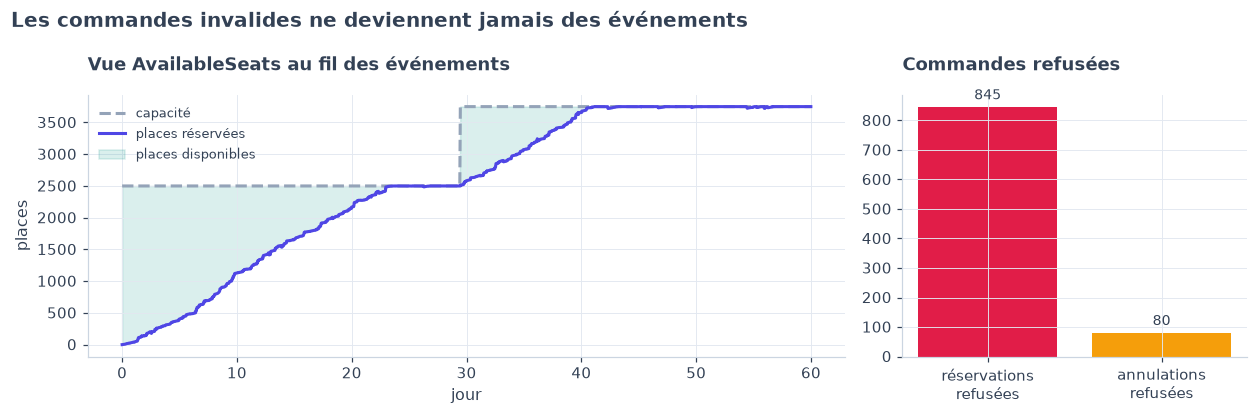

In [4]:
rej = pd.Series([c["cmd"] for _, c in svc.rejected]).value_counts()
dispo = pd.DataFrame(dispo, columns=["ts", "disponibles", "capacité"])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.plot(dispo.ts / 86400, dispo["capacité"], color=GRAY, ls="--", label="capacité")
ax.plot(dispo.ts / 86400, dispo["capacité"] - dispo["disponibles"], color=INDIGO, label="places réservées")
ax.fill_between(dispo.ts / 86400, dispo["capacité"] - dispo["disponibles"], dispo["capacité"], color=TEAL, alpha=0.15,
                label="places disponibles")
ax.set_xlabel("jour"); ax.set_ylabel("places"); ax.legend(fontsize=8.5)
ax.set_title("Vue AvailableSeats au fil des événements")
axes[1].bar(["réservations\nrefusées", "annulations\nrefusées"],
            [rej.get("book", 0), rej.get("cancel", 0)], color=[ROSE, AMBER])
annotate_bars(axes[1], "{:.0f}"); axes[1].set_title("Commandes refusées")
finish(fig, "Les commandes invalides ne deviennent jamais des événements")

Les réservations refusées sont celles qui arrivent quand la salle est pleine (avant le
changement de salle, puis à nouveau à la fin) ; les annulations refusées portent sur une
réservation déjà annulée. Aucune ne laisse de trace dans le journal. Chaque projection
présente les mêmes faits sous une forme différente :

In [5]:
print("état des réservations :", dict(list(statut.status.items())[:2]))
print("badges à imprimer     :", len(badges.badges), "dont", badges.badges[:3])
dash.frame().head()

état des réservations : {'R00000': {'client': 'participant 0', 'places': 1, 'etat': 'annulée'}, 'R00001': {'client': 'participant 1', 'places': 1, 'etat': 'confirmée'}}
badges à imprimer     : 3750 dont ['participant 1 #1', 'participant 2 #1', 'participant 3 #1']


,reservations,places,annulations
0,43,43,2
1,39,112,9
2,52,138,11
3,41,78,4
4,45,89,4


Les projections sont mises à jour **après** l'ajout de l'événement, souvent de façon
asynchrone par un autre processus. Un utilisateur qui lit une vue juste après sa
commande peut donc la trouver **en retard** : c'est le prix de la séparation écriture /
lecture, que nous retrouverons avec le retard de réplication (chapitre
6) et le traitement de flux (chapitre 12).

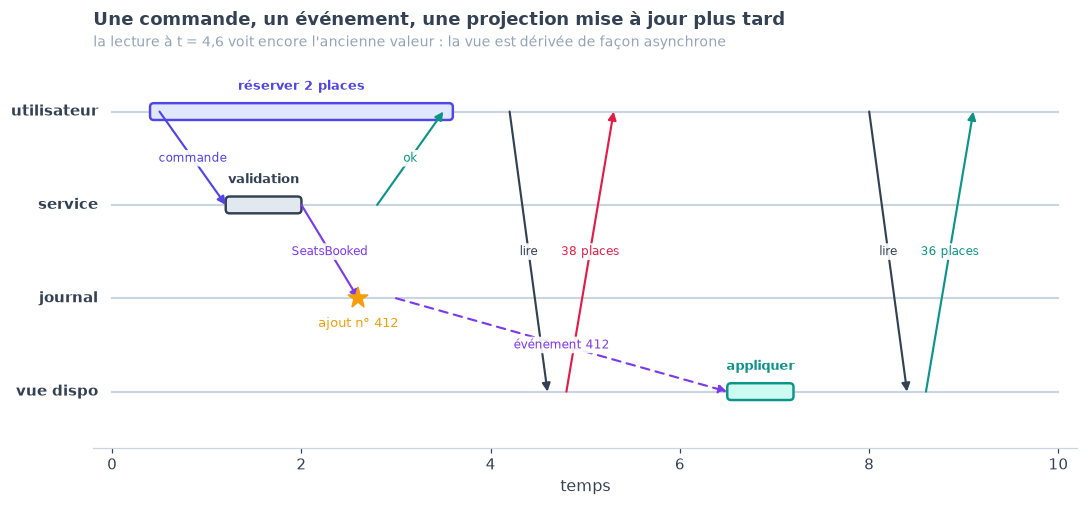

In [6]:
st = SpaceTime(["utilisateur", "service", "journal", "vue dispo"], t_max=10,
               title="Une commande, un événement, une projection mise à jour plus tard",
               subtitle="la lecture à t = 4,6 voit encore l'ancienne valeur : la vue est dérivée de façon asynchrone")
st.op("utilisateur", 0.4, 3.6, "réserver 2 places", color=INDIGO)
st.msg("utilisateur", 0.5, "service", 1.2, "commande", color=INDIGO)
st.op("service", 1.2, 2.0, "validation", color=SLATE)
st.msg("service", 2.0, "journal", 2.6, "SeatsBooked", color=VIOLET)
st.event("journal", 2.6, "ajout n° 412", kind="star")
st.msg("service", 2.8, "utilisateur", 3.5, "ok", color=TEAL)
st.msg("utilisateur", 4.2, "vue dispo", 4.6, "lire", color=SLATE)
st.msg("vue dispo", 4.8, "utilisateur", 5.3, "38 places", color=ROSE)
st.msg("journal", 3.0, "vue dispo", 6.5, "événement 412", color=VIOLET, style="dashed")
st.op("vue dispo", 6.5, 7.2, "appliquer", color=TEAL)
st.msg("utilisateur", 8.0, "vue dispo", 8.4, "lire", color=SLATE)
st.msg("vue dispo", 8.6, "utilisateur", 9.1, "36 places", color=TEAL)
st.show()

> **À retenir.** Le service valide les commandes et n'écrit que des faits ; chaque
> projection consomme les mêmes événements pour bâtir sa propre représentation. Une
> projection mise à jour de façon asynchrone peut être momentanément en retard.

## 3. Rejouer le journal : reconstruire, corriger, ajouter une vue

Le principe clé de l'event sourcing : les vues sont dérivées du journal de façon
**reproductible**. On doit toujours pouvoir les **supprimer** et les **recalculer** en
rejouant les mêmes événements, dans le même ordre, avec le même code. Les avantages
listés par le livre en découlent :

- **corriger un bogue** dans le code d'une vue : on corrige, on supprime la vue, on
  rejoue ;
- **ajouter une vue** pour une nouvelle fonctionnalité, à partir de tout l'historique ;
- **annuler une erreur** en ajoutant un événement correctif, que toutes les vues
  intègrent automatiquement (bien plus simple qu'annuler une transaction validée) ;
- un **journal d'audit** complet, précieux dans les secteurs réglementés ;
- des événements qui disent **pourquoi** les choses ont changé (« la réservation a été
  annulée ») plutôt que quelles lignes ont bougé ;
- un **débit d'écriture élevé** (ajouts séquentiels), le journal absorbant les pics
  pendant que les vues rattrapent leur retard à leur rythme.

Illustrons les deux premiers points. Une première version du tableau de bord comptait,
par erreur, les annulations comme des réservations.

In [7]:
class DashboardBogue(e2.DailyDashboard):
    def apply(self, ev):
        if ev.type in ("SeatsBooked", "BookingCancelled"):        # bogue : les annulations comptées
            self.rows[int(ev.ts // 86400)]["reservations"] += 1

class ListeAttente:
    """Nouvelle vue, ajoutée après coup : les places libérées par une annulation après remplissage."""
    def __init__(self):
        self.seats = e2.AvailableSeats()
        self.liberees_apres_complet = 0
        self.complet = False
    def apply(self, ev):
        self.seats.apply(ev)
        if self.seats.available <= 0:
            self.complet = True
        if ev.type == "BookingCancelled" and self.complet:
            self.liberees_apres_complet += 1

bogue = e2.replay(svc.log.events, DashboardBogue()).frame()["reservations"].sum()
t0 = time.perf_counter()
corrige = e2.replay(svc.log.events, e2.DailyDashboard()).frame()["reservations"].sum()
t_rejeu = time.perf_counter() - t0
attente = e2.replay(svc.log.events, ListeAttente())
print(f"réservations comptées : avec le bogue {bogue}, après correction et rejeu {corrige} "
      f"({len(svc.log.events)} événements rejoués en " + f"{t_rejeu * 1e3:.1f}".replace(".", ",") + " ms)")
print(f"nouvelle vue : {attente.liberees_apres_complet} annulations ont libéré des places après le premier remplissage")

réservations comptées : avec le bogue 2074, après correction et rejeu 1810 (2076 événements rejoués en 0,7 ms)
nouvelle vue : 141 annulations ont libéré des places après le premier remplissage


Le rejeu a un coût proportionnel à la longueur du journal. Pour ne pas tout rejouer à
chaque redémarrage, on prend des **instantanés** (*snapshots*) de la vue tous les $k$
événements : un redémarrage charge le dernier instantané et ne rejoue que la suite.
Mesurons le temps de reconstruction en fonction de la taille du journal.

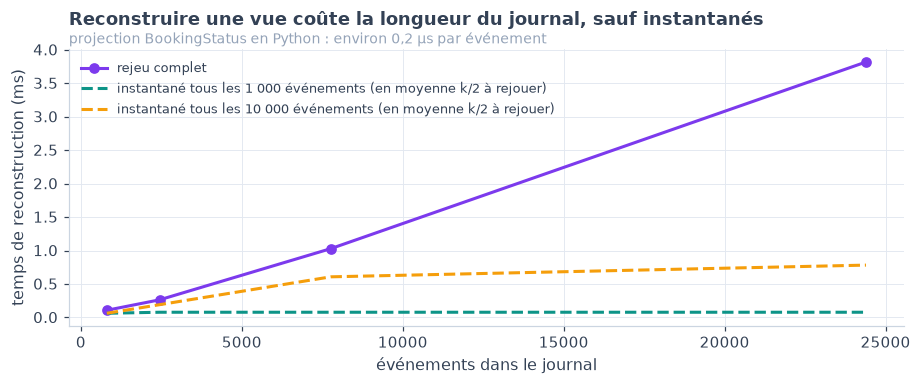

In [8]:
tailles, temps = [], []
for n in [1000, 3000, 10_000, 30_000]:
    s2 = e2.ConferenceService()
    for ts, c in e2.make_conference_commands(n, capacity=n, seed=2):
        s2.handle(c, ts)
    t0 = time.perf_counter()
    for _ in range(3):
        e2.replay(s2.log.events, e2.BookingStatus())
    tailles.append(len(s2.log.events)); temps.append((time.perf_counter() - t0) / 3 * 1e3)
per_ev = temps[-1] / tailles[-1] * 1e3
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(tailles, temps, marker="o", color=VIOLET, label="rejeu complet")
for k, col in [(1000, TEAL), (10_000, AMBER)]:
    ax.plot(tailles, [min(n, k) * per_ev / 1e3 / 2 for n in tailles], ls="--", color=col,
            label=f"instantané tous les {fmt(k)} événements (en moyenne k/2 à rejouer)")
ax.set_xlabel("événements dans le journal"); ax.set_ylabel("temps de reconstruction (ms)")
ax.set_title("Reconstruire une vue coûte la longueur du journal, sauf instantanés")
subtitle(ax, f"projection BookingStatus en Python : environ {per_ev:.1f} µs par événement".replace(".", ","))
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

**L'ordre est essentiel.** Une exigence domine toutes les autres : toutes les vues doivent
traiter les événements **exactement dans l'ordre du journal**. Rejouer une annulation
avant la réservation qu'elle annule n'a aucun sens :

In [9]:
melange = list(svc.log.events)
np.random.default_rng(3).shuffle(melange)
try:
    e2.replay(melange, e2.AvailableSeats())
except KeyError as exc:
    print("rejeu dans le désordre : échec, annulation d'une réservation inconnue", exc)

rejeu dans le désordre : échec, annulation d'une réservation inconnue 'R00522'


Garantir cet ordre n'a rien d'évident dans un système distribué (chapitre
10). C'est aussi ce qui distingue le journal d'une **table de faits**
(cours 2) : toutes deux sont des collections d'événements passés, mais les lignes d'une
table de faits ont toutes les mêmes colonnes et ne sont pas ordonnées, alors que le
journal mêle des types d'événements variés et que son ordre compte.

> **À retenir.** Les vues se reconstruisent en rejouant le journal dans le même ordre
> avec le même code : on corrige un bogue ou on ajoute une vue sans toucher aux données
> sources. Le coût du rejeu croît avec le journal (d'où les instantanés), et l'ordre doit
> être strictement respecté.

## 4. Les pièges de l'event sourcing

Le livre en signale trois.

**1. Les informations externes.** Supposons qu'une vue convertisse les prix en dollars.
Si elle va chercher le **taux de change du jour** au moment où elle traite l'événement,
un rejeu ultérieur donnera un résultat **différent**. Pour que le traitement reste
déterministe, il faut stocker le taux dans l'événement, ou interroger le taux
**historique** à la date de l'événement.

In [10]:
taux_du_jour = {"lundi": 1.08, "mardi": 1.12}            # le taux « actuel » change d'un jour à l'autre
evts = [{"prix_eur": 450, "taux_au_moment": 1.07}, {"prix_eur": 120, "taux_au_moment": 1.09}]
for jour in ["lundi", "mardi"]:
    naif = sum(e["prix_eur"] * taux_du_jour[jour] for e in evts)
    det = sum(e["prix_eur"] * e["taux_au_moment"] for e in evts)
    print(f"rejeu {jour:6} : taux du jour -> {naif:.2f} $ ; taux stocké dans l'événement -> {det:.2f} $")

rejeu lundi  : taux du jour -> 615.60 $ ; taux stocké dans l'événement -> 612.30 $
rejeu mardi  : taux du jour -> 638.40 $ ; taux stocké dans l'événement -> 612.30 $


**2. Les données personnelles.** L'immuabilité des événements se heurte au droit des
personnes à faire effacer leurs données (par exemple au titre du RGPD). Si le journal est
propre à un utilisateur, on peut le supprimer en entier ; sinon, on stocke les données
personnelles hors de l'événement, ou on les **chiffre** avec une clé propre à
l'utilisateur, qu'on détruit pour les rendre illisibles : c'est le *crypto-shredding*.
Démonstration avec un chiffrement jouet (un masque dérivé de la clé ; ne jamais l'utiliser
en vrai) :

In [11]:
cles = {u: hashlib.sha256(f"clé secrète {u}".encode()).digest() for u in ["alice", "bruno"]}

def xor_masque(data, cle):
    masque = (cle * (len(data) // len(cle) + 1))[:len(data)]
    return bytes(a ^ b for a, b in zip(data, masque))

chiffre = lambda texte, cle: xor_masque(texte.encode(), cle)
dechiffre = lambda octets, cle: xor_masque(octets, cle).decode()
journal = [{"type": "SeatsBooked", "user": u, "nom_chiffre": chiffre(nom, cles[u]), "places": p}
           for u, nom, p in [("alice", "Alice Dupont", 1), ("bruno", "Bruno Keller", 3)]]

def badges_vue(journal, cles):
    return [dechiffre(e["nom_chiffre"], cles[e["user"]]) if e["user"] in cles else "[effacé]" for e in journal]

print("avant effacement :", badges_vue(journal, cles))
del cles["bruno"]                                          # Bruno demande l'effacement : on détruit sa clé
print("après effacement :", badges_vue(journal, cles), "; le journal n'a pas été modifié :", len(journal), "événements")

avant effacement : ['Alice Dupont', 'Bruno Keller']
après effacement : ['Alice Dupont', '[effacé]'] ; le journal n'a pas été modifié : 2 événements


Le journal reste intact et rejouable, mais les données de Bruno sont devenues illisibles
pour toujours ; la contrepartie est qu'aucune vue ne pourra plus jamais les recalculer.

**3. Les effets de bord.** Rejouer des événements ne doit pas renvoyer les e-mails de
confirmation à chaque reconstruction d'une vue. Les effets visibles de l'extérieur
doivent être séparés du calcul des vues, ou marqués pour n'être exécutés qu'une fois.

On peut implémenter l'event sourcing sur n'importe quelle base, mais certains systèmes
sont faits pour cela (EventStoreDB, MartenDB sur PostgreSQL, Axon Framework), et l'on
peut aussi stocker le journal dans un courtier de messages comme Kafka, des processeurs de
flux tenant les vues à jour (chapitre 12).

> **À retenir.** Un traitement d'événements doit être déterministe (pas de donnée externe
> « du jour »), compatible avec l'effacement des données personnelles (stockage séparé ou
> crypto-shredding) et sans effet de bord au rejeu.

## 5. DataFrames, matrices et tableaux (section *DataFrames, Matrices, and Arrays*)

Les modèles précédents servent aussi bien le transactionnel que l'analytique. Certains
modèles, en revanche, se rencontrent surtout en analyse ou en calcul scientifique : les
**DataFrames** et les **tableaux multidimensionnels** de nombres, comme les matrices.

Un DataFrame (R, la bibliothèque pandas de Python, Spark, Dask...) ressemble à première
vue à une table relationnelle ou à un tableur. Il offre des opérations de masse proches
du relationnel : appliquer une fonction à toutes les lignes, filtrer, grouper et agréger,
joindre deux DataFrames (on dit souvent *merge*). Mais on le manipule par une **suite de
commandes** qui transforment progressivement sa structure, plutôt que par une requête
déclarative : c'est le travail exploratoire du *data scientist*, souvent sur sa propre
copie des données.

Prenons une table relationnelle de notes de films (1 à 5), générée par
`e2.make_ratings` : 5 000 utilisateurs, 1 000 films.

In [12]:
notes = e2.make_ratings(5000, 1000, per_user=30, seed=0)
films = pd.DataFrame({"movie_id": range(1000),
                      "genre": rng.choice(["comédie", "drame", "horreur", "SF", "animation"], 1000),
                      "annee": rng.integers(1960, 2025, 1000)})
etapes = (notes
          .merge(films, on="movie_id")                         # jointure (merge)
          .query("annee >= 2000")                              # filtre
          .groupby("genre")["rating"].agg(["count", "mean"])   # regroupement et agrégation
          .sort_values("mean", ascending=False))
print(f"{fmt(len(notes))} notes ;", f"densité de la matrice : {len(notes) / (5000 * 1000):.2%}".replace(".", ","))
etapes

150 295 notes ; densité de la matrice : 3,01%


,count,mean
genre,,
SF,7861,3.012
horreur,8676,3.010
drame,11281,3.006
comédie,11321,2.984
animation,10737,2.983


Un usage courant des DataFrames, très éloigné de la modélisation relationnelle, consiste
à transformer une table en **matrice** : une ligne par utilisateur, une colonne par film,
la note dans la case (comme un tableau croisé dynamique). La matrice est **creuse** : la
plupart des combinaisons n'ont pas de note. Elle peut avoir des milliers de colonnes, ce
qu'une base relationnelle gère mal, mais que les DataFrames et les bibliothèques de
tableaux creux gèrent sans peine.

In [13]:
pivot = notes.pivot_table(index="user_id", columns="movie_id", values="rating")
print("pivot :", pivot.shape, "; cases vides :", f"{pivot.isna().mean().mean():.1%}".replace(".", ","))
pivot.iloc[:5, :8]

pivot : (5000, 1000) ; cases vides : 97,0%


movie_id,0,1,2,3,4,5,6,7
user_id,,,,,,,,
0,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
1,4.0,2.0,5.0,NaN,1.0,4.0,3.0,2.0
2,3.0,3.0,1.0,NaN,3.0,NaN,NaN,4.0
3,3.0,2.0,NaN,5.0,NaN,NaN,4.0,1.0
4,4.0,NaN,NaN,2.0,NaN,5.0,NaN,NaN


Une matrice **dense** stocke toutes les cases ; un format **creux** comme CSR
(*compressed sparse row*, écrit à la main dans `e2.to_csr`) ne stocke que les valeurs
non nulles, leurs colonnes et un tableau d'index de début de ligne. Comparons les
tailles quand le nombre d'utilisateurs grandit, à 30 notes par utilisateur.

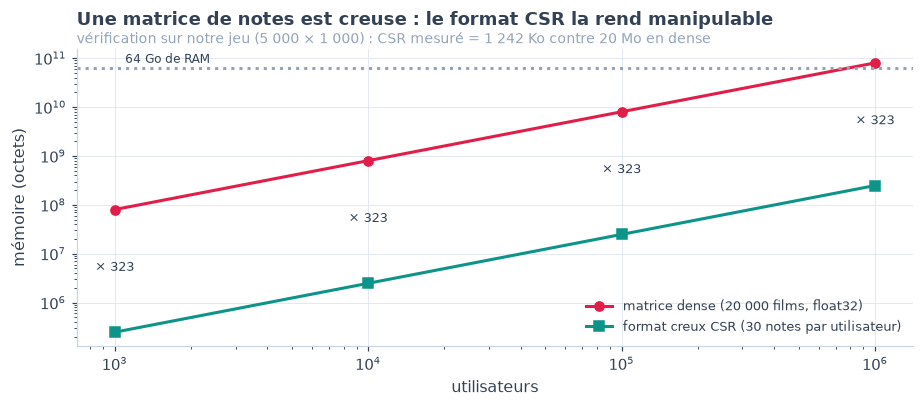

In [14]:
users_n = [1_000, 10_000, 100_000, 1_000_000]
n_films = 20_000
dense = [float(u * n_films * 4) for u in users_n]                      # float32
csr = [float(u * 30 * (4 + 4) + (u + 1) * 8) for u in users_n]         # valeurs + colonnes + indptr
mesure = e2.csr_nbytes(e2.to_csr(notes.user_id, notes.movie_id, notes.rating, (5000, 1000)))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.loglog(users_n, dense, marker="o", color=ROSE, label=f"matrice dense ({fmt(n_films)} films, float32)")
ax.loglog(users_n, csr, marker="s", color=TEAL, label="format creux CSR (30 notes par utilisateur)")
for u, a, b in zip(users_n, dense, csr):
    ax.annotate(f"× {a / b:,.0f}".replace(",", " "), (u, np.sqrt(a * b)), ha="center", fontsize=8.5, color=SLATE)
ax.axhline(64e9, color=GRAY, ls=":"); ax.text(1100, 80e9, "64 Go de RAM", fontsize=8, color=SLATE)
ax.set_xlabel("utilisateurs"); ax.set_ylabel("mémoire (octets)")
ax.set_title("Une matrice de notes est creuse : le format CSR la rend manipulable")
subtitle(ax, f"vérification sur notre jeu (5 000 × 1 000) : CSR mesuré = {fmt(mesure / 1e3)} Ko contre {5000 * 1000 * 4 / 1e6:.0f} Mo en dense")
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

Une matrice ne contient que des **nombres** ; il faut donc encoder le reste. Les dates
peuvent être ramenées à des flottants dans un intervalle adapté ; une colonne à valeurs
dans un petit ensemble fixe (le genre d'un film) se traite par **encodage one-hot** : une
colonne par valeur possible, 1 dans la colonne du genre du film, 0 ailleurs (ce qui
s'étend sans peine aux films de plusieurs genres).

In [15]:
one_hot = pd.get_dummies(films.set_index("movie_id")["genre"], dtype=int)
films_num = one_hot.assign(annee_norm=(films.set_index("movie_id")["annee"] - 1960) / (2025 - 1960))
films_num.head()

,SF,animation,comédie,drame,horreur,annee_norm
movie_id,,,,,,
0,0,1,0,0,0,0.538
1,1,0,0,0,0,0.077
2,0,0,0,0,1,0.185
3,0,0,0,1,0,0.862
4,0,0,0,1,0,0.431


Une fois en matrice, les données se prêtent à l'**algèbre linéaire**, base de nombreux
algorithmes d'apprentissage. Exemple minimal de recommandation : la similarité cosinus
entre les colonnes de la matrice de notes (centrées autour de 3) trouve les films
« appréciés par les mêmes personnes ». Comparons les cinq voisins du film le plus noté à
cinq films tirés au hasard.

In [16]:
M = pivot.fillna(0).to_numpy(dtype=np.float32)
centre = np.where(M > 0, M - 3, 0)                         # notes centrées : 0 = pas d'avis
film_ref = int(notes.movie_id.value_counts().index[0])
col = list(pivot.columns).index(film_ref)
voisins = e2.cosine_top_k(centre, col, k=5)
hasard = rng.choice(M.shape[1], 5, replace=False)
pd.DataFrame({"film": [int(pivot.columns[j]) for j, _ in voisins] + [int(pivot.columns[j]) for j in hasard],
              "choisi par": ["similarité cosinus"] * 5 + ["hasard"] * 5,
              "cosinus": [s for _, s in voisins] + [float(np.dot(centre[:, col], centre[:, j]) /
                                                         (np.linalg.norm(centre[:, col]) * np.linalg.norm(centre[:, j]) + 1e-9))
                                                  for j in hasard]}).round(3)

,film,choisi par,cosinus
0,5,similarité cosinus,0.540
1,2,similarité cosinus,0.519
2,17,similarité cosinus,0.371
3,22,similarité cosinus,0.353
4,18,similarité cosinus,0.308
5,739,hasard,-0.038
6,774,hasard,0.061
7,826,hasard,-0.075
8,12,hasard,-0.097
9,515,hasard,-0.016


Les cinq films les plus proches du film le plus noté ont un cosinus nettement positif,
là où des films tirés au hasard tournent autour de zéro : la matrice a capturé une
structure de goûts. Les DataFrames permettent de passer progressivement d'une forme
relationnelle à une forme matricielle, en gardant la main sur la représentation.

Certaines bases, comme TileDB, sont spécialisées dans les **tableaux multidimensionnels**
(bases de tableaux) : données géospatiales en grille, imagerie médicale, observations de
télescopes. Les DataFrames servent aussi en finance pour les séries temporelles, et ils
ont été ajoutés aux frameworks de traitement par lots comme Spark et Flink (chapitre
11).

> **À retenir.** Un DataFrame offre des opérations proches du relationnel par une suite
> de commandes, et sert de pont vers les matrices qu'attend l'apprentissage automatique :
> pivot, encodage one-hot, format creux pour les matrices clairsemées.

## Synthèse

- L'**event sourcing** écrit un journal d'événements immuables, nommés au passé, qui ne
  contient que des commandes validées ; **CQRS** en dérive autant de vues de lecture que
  nécessaire.
- Les vues se **reconstruisent** par rejeu, ce qui permet de corriger un bogue, d'ajouter
  une vue, d'auditer ; il faut un traitement déterministe, un ordre strict, des
  instantanés pour les longs journaux, et une solution pour effacer les données
  personnelles.
- Les **DataFrames** relient le monde relationnel aux **matrices** de l'apprentissage
  automatique ; les matrices réelles sont creuses.
- D'autres modèles existent encore : recherche de similarité de séquences génomiques,
  **registres en partie double** des systèmes financiers, recherche plein texte (chapitre
  4).

Les journaux en ajout seul sont au cœur des moteurs de stockage du chapitre
4 ; l'event sourcing et les vues dérivées reviennent en force avec le
traitement de flux (chapitre 12).